# Diagnosing weak instrumental variables

A valid instrument changes treatment, affects outcome only through treatment, and is independent of the unmeasured causes of the outcome:

$$
\operatorname{Cov}(Z,X)\neq0,
\qquad
Y(x,z)=Y(x),
\qquad
Z\mathbin{\perp\!\!\!\perp}\{Y(x),X(z)\}.
$$

Here, $Z$ is the instrument, $X$ is treatment, $Y$ is outcome, $Y(x,z)$ is the potential outcome under treatment $x$ and instrument $z$, $Y(x)$ records the exclusion restriction, and $X(z)$ is the potential treatment under instrument value $z$. The first condition is relevance; the last two require substantive design arguments.

## Notebook setup

### Number formatting for tables

In [ ]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered




### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd



## Display float

In [ ]:
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

sys.path.insert(0, str(ROOT))
from causal_notebook_tools import AndersonRubinSet, DirectPathTest, FrontDoorResult, IVPremium, IVWedgeResult, anderson_rubin_set, backdoor_adjustment_set, direct_path_test, flag_controls, frontdoor_analysis, frontdoor_ols_wedge, frontdoor_premium, frontdoor_sensitivity_interval, in_anderson_rubin_set, iv_premium, iv_wedge_analysis, ols_iv_wedge, ols_premium

FIGURES = ROOT / "outputs" / "figures" / "02_graphical_identification"
TABLES = ROOT / "outputs" / "tables" / "02_graphical_identification"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float);



## Table display and number formatting

In [ ]:
def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display_notebook_figure(figure)
    plt.close(figure)



## Draw graph

In [ ]:
def draw_graph(axis, graph, positions, title, latent=None, labels=None):
    latent = set() if latent is None else set(latent)
    node_colors = [palette["violet"] if node in latent else palette["cyan"] for node in graph.nodes]
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=node_colors, node_size=2200, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, labels=labels, font_color=palette["background"], font_weight="bold", font_size=8.5)
    solid = [(u, v) for u, v in graph.edges if u not in latent]
    dashed = [(u, v) for u, v in graph.edges if u in latent]
    nx.draw_networkx_edges(graph, positions, ax=axis, edgelist=solid, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    nx.draw_networkx_edges(graph, positions, ax=axis, edgelist=dashed, edge_color=palette["violet"], width=1.8, style="dashed", arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    axis.set_title(title)
    axis.set_axis_off()

def ols_slope(outcome, treatment, controls=None):
    columns = [np.asarray(treatment, dtype=float)]
    if controls is not None:
        control_values = np.asarray(controls, dtype=float)
        if control_values.ndim == 1:
            control_values = control_values.reshape(-1, 1)
        columns.extend(control_values[:, j] for j in range(control_values.shape[1]))
    design = np.column_stack([np.ones(len(outcome))] + columns)
    return float(np.linalg.lstsq(design, np.asarray(outcome, dtype=float), rcond=None)[0][1])

def mean_squared_error(values, truth):
    numbers = np.asarray(values, dtype=float)
    return float(np.mean((numbers - truth) ** 2))



## Three distinct requirements for an instrument

,Condition,Question,Observable implication,Enough by itself
0,Relevance,Does the instrument move treatment?,Nonzero first-stage relation,False
1,Exclusion,Does the instrument avoid a direct outcome path?,Not established by relevance,False
2,Outside variation,Is the instrument separated from unmeasured ou...,Needs a design argument,False


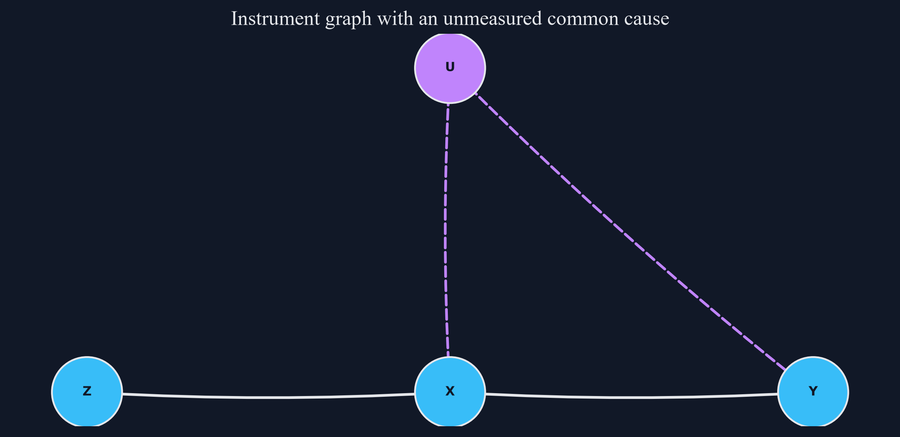

In [1]:
def contract_result(name, action, expected):
    expected_text = "Rejected" if expected in {"ValueError", "TypeError"} else expected
    try:
        action()
        return {"Check": name, "Expected result": expected_text, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        observed_text = "Rejected" if type(error).__name__ in {"ValueError", "TypeError"} else "Different rejection"
        return {"Check": name, "Expected result": expected_text, "Observed result": observed_text, "Passed": type(error).__name__ == expected}

iv_graph = nx.DiGraph([("Z", "X"), ("X", "Y"), ("U", "X"), ("U", "Y")])
positions = {"Z": (0, 0), "X": (1.5, 0), "Y": (3, 0), "U": (1.5, 1.2)}
iv_conditions = pd.DataFrame([
    {"Condition": "Relevance", "Question": "Does the instrument move treatment?", "Observable implication": "Nonzero first-stage relation", "Enough by itself": False},
    {"Condition": "Exclusion", "Question": "Does the instrument avoid a direct outcome path?", "Observable implication": "Not established by relevance", "Enough by itself": False},
    {"Condition": "Outside variation", "Question": "Is the instrument separated from unmeasured outcome causes?", "Observable implication": "Needs a design argument", "Enough by itself": False},
])
save_table(iv_conditions, "iv_conditions", "Three distinct requirements for an instrument.", "tab:chapter24-iv-conditions")
display(iv_conditions)

figure, axis = plt.subplots(figsize=(8.5, 4.2))
draw_graph(axis, iv_graph, positions, "Instrument graph with an unmeasured common cause", latent={"U"})
figure.tight_layout()
save_figure(figure, "iv_graph")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Relating estimate stability to instrument strength

With one instrument and an intercept, the instrumental-variable point estimate is a ratio of sample covariances:

$$
\widehat\beta_{\mathrm{IV}}
=\frac{\widehat{\operatorname{Cov}}(Z,Y)}{\widehat{\operatorname{Cov}}(Z,X)}.
$$

Here, $\widehat\beta_{\mathrm{IV}}$ is the just-identified effect estimate, $Z$ is the instrument, $X$ is treatment, $Y$ is outcome, and the denominator measures how strongly the instrument moves treatment.

The first-stage strength statistic for one excluded instrument is the squared fitted instrument coefficient divided by its estimated variance:

$$
F=\frac{\widehat\pi^2}{\widehat{\operatorname{Var}}(\widehat\pi)},
\qquad
X=\alpha_X+\pi Z+v.
$$

Here, $F$ is the first-stage statistic, $\widehat\pi$ is the fitted instrument coefficient, $\widehat{\operatorname{Var}}(\widehat\pi)$ is its estimated variance, $\alpha_X$ is an intercept, and $v$ is the first-stage residual. The value 10 is used below as a practical warning line, not as proof of validity.

The generated panel fixes the causal effect while changing only instrument relevance and confounding strength:

$$
X=\pi Z+\phi U+\varepsilon_X,
\qquad
Y=\beta X+\gamma U+\varepsilon_Y,
\qquad
W=U+\kappa\varepsilon_W.
$$

Here, $U$ is the unmeasured common cause, $Z$ is the instrument, $W$ is a noisy proxy for the common cause, $\beta$ is the known treatment effect, $\pi$ is instrument relevance, $\phi$ and $\gamma$ are the common-cause loadings, $\kappa$ controls proxy noise, and the three $\varepsilon$ terms are independent standard-normal shocks.

### Values used in the instrumental-variable experiments

In [2]:
beta_true = 0.5
phi = 1.0

def simulate_iv(n, gamma=1.0, relevance=1.0, proxy_noise=3.0, rng=None):
    generator = np.random.default_rng() if rng is None else rng
    common = generator.standard_normal(n)
    instrument = generator.standard_normal(n)
    treatment_values = relevance * instrument + phi * common + generator.standard_normal(n)
    outcome_values = beta_true * treatment_values + gamma * common + generator.standard_normal(n)
    proxy = common + proxy_noise * generator.standard_normal(n)
    return treatment_values, outcome_values, instrument, proxy

def proxy_controlled_slope(outcome_values, treatment_values, proxy):
    return ols_slope(outcome_values, treatment_values, proxy)

iv_parameters = pd.DataFrame([
    {"Parameter": "Known treatment effect", "Symbol": "beta", "Value": beta_true},
    {"Parameter": "Common-cause loading on treatment", "Symbol": "phi", "Value": phi},
    {"Parameter": "Observations in released example", "Symbol": "n", "Value": 3000},
    {"Parameter": "Strong-warning line", "Symbol": "F", "Value": 10},
    {"Parameter": "Confidence level", "Symbol": "one minus alpha", "Value": 0.95},
])
demo_rng = np.random.default_rng(20260707)
demo_rows = []
for relevance in (0.60, 0.12, 0.04):
    x, y, z, w = simulate_iv(3000, gamma=1.0, relevance=relevance, rng=demo_rng)
    result = iv_wedge_analysis(x, y, z)
    wald = result.iv.wald_ci
    demo_rows.append({"Instrument relevance": relevance, "First-stage F": result.iv.first_stage_f, "Strong by warning line": result.strong_instrument, "Ordinary estimate": result.ols_premium, "Instrumental estimate": result.iv.beta, "Wedge": result.wedge, "Ordinary interval low": wald[0] if wald is not None else np.nan, "Ordinary interval high": wald[1] if wald is not None else np.nan, "Robust set kind": result.ar_set.kind, "Robust set low": result.ar_set.lo, "Robust set high": result.ar_set.hi})
iv_demo = pd.DataFrame(demo_rows)
save_table(iv_parameters, "iv_structural_parameters", "Values used in the instrumental-variable experiments.", "tab:chapter24-iv-parameters")
iv_demo_book = iv_demo[["Instrument relevance", "First-stage F", "Ordinary estimate", "Instrumental estimate", "Robust set kind"]]
save_table(iv_demo_book, "iv_demo", "Point estimates, strength, and robust-set shape across three instrument strengths.", "tab:chapter24-iv-demo")
display(iv_parameters)
display(iv_demo);



,Parameter,Symbol,Value
0,Known treatment effect,beta,0.5
1,Common-cause loading on treatment,phi,1
2,Observations in released example,n,3000
3,Strong-warning line,F,10
4,Confidence level,one minus alpha,0.95


,Instrument relevance,First-stage F,Strong by warning line,Ordinary estimate,Instrumental estimate,Wedge,Ordinary interval low,Ordinary interval high,Robust set kind,Robust set low,Robust set high
0,0.6,528.723305,True,0.910294,0.47274,0.437554,0.386534,0.558945,interval,0.382311,0.555627
1,0.12,8.587583,False,1.021306,0.137811,0.883494,-0.682897,0.958519,interval,-1.898623,0.737504
2,0.04,2.414536,False,1.033589,0.686781,0.346808,-0.489858,1.863419,allreal,-inf,inf


### First-stage strength

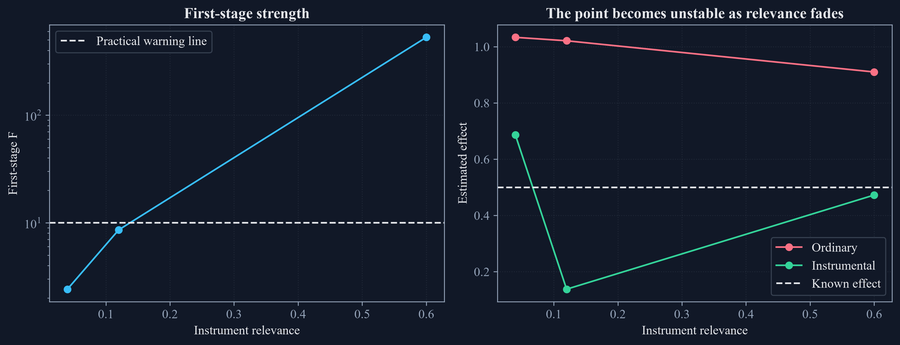

In [2]:
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
axes[0].plot(iv_demo["Instrument relevance"], iv_demo["First-stage F"], marker="o", color=palette["cyan"])
axes[0].axhline(10, color=palette["text"], linestyle="--", label="Practical warning line")
axes[0].set_yscale("log")
axes[0].set_xlabel("Instrument relevance")
axes[0].set_ylabel("First-stage F")
axes[0].set_title("First-stage strength")
axes[0].legend()
axes[1].plot(iv_demo["Instrument relevance"], iv_demo["Ordinary estimate"], marker="o", color=palette["rose"], label="Ordinary")
axes[1].plot(iv_demo["Instrument relevance"], iv_demo["Instrumental estimate"], marker="o", color=palette["green"], label="Instrumental")
axes[1].axhline(beta_true, color=palette["text"], linestyle="--", label="Known effect")
axes[1].set_xlabel("Instrument relevance")
axes[1].set_ylabel("Estimated effect")
axes[1].set_title("The point becomes unstable as relevance fades")
axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.4)
figure.tight_layout()
save_figure(figure, "iv_demo_strength")

## Recovering the effect with a strong instrument

The ordinary-versus-instrumental wedge records the absolute distance between two fitted effects:

$$
W_{\mathrm{IV}}=\left|\widehat\beta_{\mathrm{OLS}}-\widehat\beta_{\mathrm{IV}}\right|.
$$

Here, $W_{\mathrm{IV}}$ is the diagnostic wedge, $\widehat\beta_{\mathrm{OLS}}$ is the ordinary treatment slope, and $\widehat\beta_{\mathrm{IV}}$ is the instrumental-variable estimate. The wedge can reveal disagreement under a valid strong instrument, but it cannot establish exclusion or outside variation.

### Repeated-sample recovery with a strong valid instrument

In [3]:
repetitions = 400
observations = 2000
recovery_rng = np.random.default_rng(80808081)
recovery = {"Instrumental": np.empty(repetitions), "Ordinary": np.empty(repetitions), "Noisy proxy adjustment": np.empty(repetitions)}
for repetition in range(repetitions):
    x, y, z, w = simulate_iv(observations, gamma=2.5, relevance=1.0, rng=recovery_rng)
    recovery["Instrumental"][repetition] = iv_premium(x, y, z).beta
    recovery["Ordinary"][repetition] = ols_premium(x, y)
    recovery["Noisy proxy adjustment"][repetition] = proxy_controlled_slope(y, x, w)
strong_recovery = pd.DataFrame([{"Method": name, "Mean estimate": values.mean(), "Bias": values.mean() - beta_true, "Mean squared error": mean_squared_error(values, beta_true), "Repetitions": repetitions} for name, values in recovery.items()])
save_table(strong_recovery, "iv_strong_recovery", "Repeated-sample recovery with a strong valid instrument.", "tab:chapter24-iv-strong-recovery")
display(strong_recovery);



,Method,Mean estimate,Bias,Mean squared error,Repetitions
0,Instrumental,0.494619,-0.005381,0.003793,400
1,Ordinary,1.334885,0.834885,0.697951,400
2,Noisy proxy adjustment,1.277107,0.777107,0.604781,400


### A strong valid instrument recovers the known effect

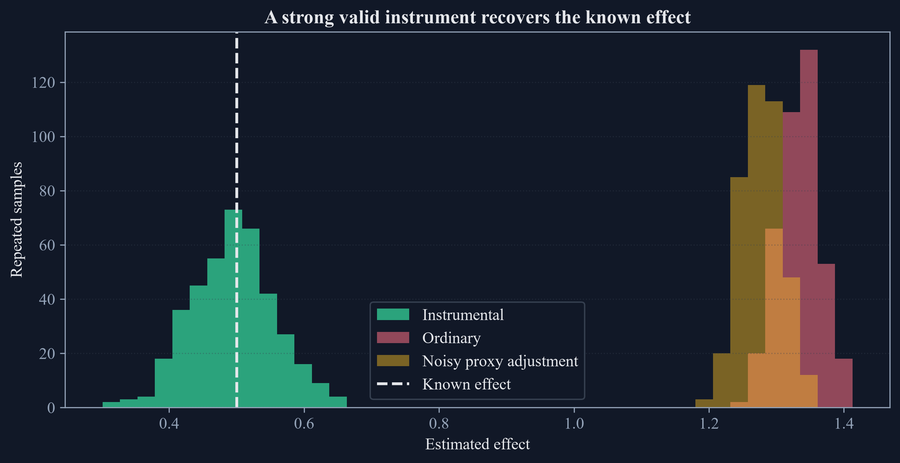

,Outcome common-cause loading,Mean wedge,Wedge standard deviation,Repetitions
0,0,0.014627,0.011791,400
1,1,0.333846,0.029255,400
2,2.5,0.833885,0.05608,400


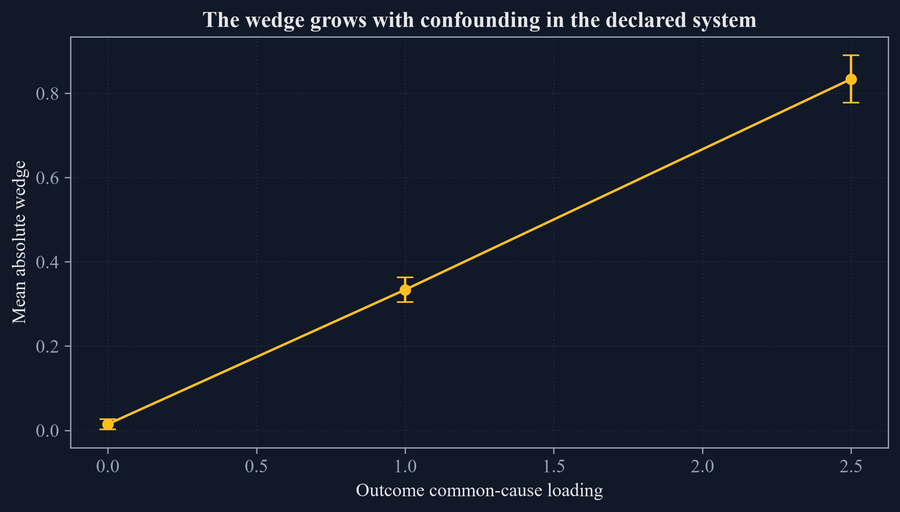

In [3]:
figure, axis = plt.subplots(figsize=(9, 4.7))
bins = np.linspace(min(values.min() for values in recovery.values()), max(values.max() for values in recovery.values()), 44)
for name, color, alpha in (("Instrumental", palette["green"], 0.75), ("Ordinary", palette["rose"], 0.55), ("Noisy proxy adjustment", palette["amber"], 0.45)):
    axis.hist(recovery[name], bins=bins, alpha=alpha, color=color, label=name)
axis.axvline(beta_true, color=palette["text"], linestyle="--", linewidth=2, label="Known effect")
axis.set_xlabel("Estimated effect")
axis.set_ylabel("Repeated samples")
axis.set_title("A strong valid instrument recovers the known effect")
axis.legend()
axis.grid(axis="y", alpha=0.35)
figure.tight_layout()
save_figure(figure, "iv_strong_recovery_distributions")

wedge_rng = np.random.default_rng(80808082)
wedge_rows = []
for gamma in (0.0, 1.0, 2.5):
    values = []
    for repetition in range(repetitions):
        x, y, z, w = simulate_iv(observations, gamma=gamma, relevance=1.0, rng=wedge_rng)
        values.append(ols_iv_wedge(x, y, z))
    wedge_rows.append({"Outcome common-cause loading": gamma, "Mean wedge": np.mean(values), "Wedge standard deviation": np.std(values, ddof=1), "Repetitions": repetitions})
iv_wedge_sweep = pd.DataFrame(wedge_rows)
save_table(iv_wedge_sweep, "iv_wedge_sweep", "Ordinary and instrumental-estimate disagreement as confounding increases.", "tab:chapter24-iv-wedge")
display(iv_wedge_sweep)

figure, axis = plt.subplots(figsize=(7.8, 4.5))
axis.errorbar(iv_wedge_sweep["Outcome common-cause loading"], iv_wedge_sweep["Mean wedge"], yerr=iv_wedge_sweep["Wedge standard deviation"], marker="o", capsize=5, color=palette["amber"])
axis.set_xlabel("Outcome common-cause loading")
axis.set_ylabel("Mean absolute wedge")
axis.set_title("The wedge grows with confounding in the declared system")
axis.grid(alpha=0.4)
figure.tight_layout()
save_figure(figure, "iv_wedge_sweep")

## Anderson-Rubin Sets

The Anderson-Rubin statistic tests a proposed effect by checking whether the instrument predicts the outcome residual formed under that effect:

$$
\operatorname{AR}(b)
=\frac{\left[Z^{\mathsf T}(Y-bX)\right]^2}
{(Z^{\mathsf T}Z)\widehat{\operatorname{Var}}(Y-bX)},
\qquad
\mathcal C_{1-\alpha}=\{b:\operatorname{AR}(b)\leq\chi^2_{1,1-\alpha}\}.
$$

Here, $b$ is a proposed treatment effect, $Y-bX$ is the residual implied by that proposal, $Z$ is the demeaned instrument vector, $\widehat{\operatorname{Var}}$ is the sample residual variance, $\chi^2_{1,1-\alpha}$ is a chi-squared critical value with one degree of freedom, and $\mathcal C_{1-\alpha}$ is the confidence set containing all proposals not rejected.

### Coverage, informativeness, and point error across instrument strength

In [4]:
ar_rng = np.random.default_rng(80808083)
ar_rows = []
for relevance in (1.0, 0.3, 0.1, 0.05):
    covered = 0
    bounded = 0
    first_stage = np.empty(repetitions)
    points = np.empty(repetitions)
    for repetition in range(repetitions):
        x, y, z, w = simulate_iv(observations, gamma=2.5, relevance=relevance, rng=ar_rng)
        covered += int(in_anderson_rubin_set(beta_true, x, y, z))
        robust_set = anderson_rubin_set(x, y, z)
        bounded += int(robust_set.bounded)
        point = iv_premium(x, y, z)
        first_stage[repetition] = point.first_stage_f
        points[repetition] = point.beta
    ar_rows.append({"Instrument relevance": relevance, "Robust-set coverage": covered / repetitions, "Bounded-set fraction": bounded / repetitions, "Median first-stage F": np.median(first_stage), "Point-estimate mean squared error": mean_squared_error(points, beta_true), "Repetitions": repetitions})
ar_sweep = pd.DataFrame(ar_rows)
ar_sweep_book = ar_sweep.rename(columns={"Instrument relevance": "Relevance", "Robust-set coverage": "Coverage", "Bounded-set fraction": "Bounded share", "Median first-stage F": "Median F", "Point-estimate mean squared error": "Point MSE", "Repetitions": "Runs"})
save_table(ar_sweep_book, "iv_ar_sweep", "Coverage, informativeness, and point error across instrument strength.", "tab:chapter24-iv-ar-sweep")
display(ar_sweep);



,Instrument relevance,Robust-set coverage,Bounded-set fraction,Median first-stage F,Point-estimate mean squared error,Repetitions
0,1,0.945,1,1002.94981,0.003655,400
1,0.3,0.9475,1,89.375038,0.045221,400
2,0.1,0.945,0.8775,9.451805,10.409358,400
3,0.05,0.9225,0.33,2.550182,116.152598,400


### Robust-set coverage

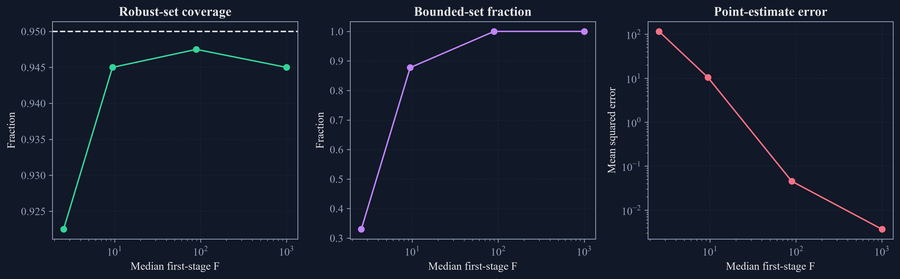

In [4]:
figure, axes = plt.subplots(1, 3, figsize=(13.2, 4.2))
axes[0].plot(ar_sweep["Median first-stage F"], ar_sweep["Robust-set coverage"], marker="o", color=palette["green"])
axes[0].axhline(0.95, color=palette["text"], linestyle="--")
axes[0].set_title("Robust-set coverage")
axes[0].set_ylabel("Fraction")
axes[1].plot(ar_sweep["Median first-stage F"], ar_sweep["Bounded-set fraction"], marker="o", color=palette["violet"])
axes[1].set_title("Bounded-set fraction")
axes[1].set_ylabel("Fraction")
axes[2].plot(ar_sweep["Median first-stage F"], ar_sweep["Point-estimate mean squared error"], marker="o", color=palette["rose"])
axes[2].set_yscale("log")
axes[2].set_title("Point-estimate error")
axes[2].set_ylabel("Mean squared error")
for axis in axes:
    axis.set_xscale("log")
    axis.set_xlabel("Median first-stage F")
    axis.grid(alpha=0.4)
figure.tight_layout()
save_figure(figure, "iv_ar_sweep")

### Understanding confidence-set limits

A confidence set becomes uninformative when it contains all sufficiently extreme candidates or the whole real line:

$$
\mathcal C_{1-\alpha}\in\{[\ell,u],\ (-\infty,u],\ [\ell,\infty),\ (-\infty,\ell]\cup[u,\infty),\ \mathbb R\}.
$$

Here, $[\ell,u]$ is a bounded interval, the next two sets are rays, the fourth is a union of two rays, and $\mathbb R$ is the whole real line. An unbounded result keeps the uncertainty visible instead of forcing a precise point.

#### Limiting comparisons with no confounding or a measured common cause

In [5]:
limiting_rng = np.random.default_rng(80808084)
limiting_values = {"Instrumental without confounding": [], "Ordinary without confounding": [], "Instrumental with measured common cause": [], "Measured-common-cause adjustment": []}
for repetition in range(repetitions):
    x, y, z, w = simulate_iv(observations, gamma=0.0, relevance=1.0, rng=limiting_rng)
    limiting_values["Instrumental without confounding"].append(iv_premium(x, y, z).beta)
    limiting_values["Ordinary without confounding"].append(ols_premium(x, y))
    xm, ym, zm, wm = simulate_iv(observations, gamma=2.5, relevance=1.0, proxy_noise=0.0, rng=limiting_rng)
    limiting_values["Instrumental with measured common cause"].append(iv_premium(xm, ym, zm).beta)
    limiting_values["Measured-common-cause adjustment"].append(proxy_controlled_slope(ym, xm, wm))
limiting_cases = pd.DataFrame([{"Case": name, "Mean estimate": np.mean(values), "Mean squared error": mean_squared_error(values, beta_true), "Repetitions": repetitions} for name, values in limiting_values.items()])
save_table(limiting_cases, "iv_limiting_cases", "Limiting comparisons with no confounding or a measured common cause.", "tab:chapter24-iv-limiting-cases")
display(limiting_cases);



,Case,Mean estimate,Mean squared error,Repetitions
0,Instrumental without confounding,0.499269,0.000474,400
1,Ordinary without confounding,0.500087,0.000165,400
2,Instrumental with measured common cause,0.502563,0.003859,400
3,Measured-common-cause adjustment,0.49975,0.000233,400


#### Valid alternatives agree in their shared cases

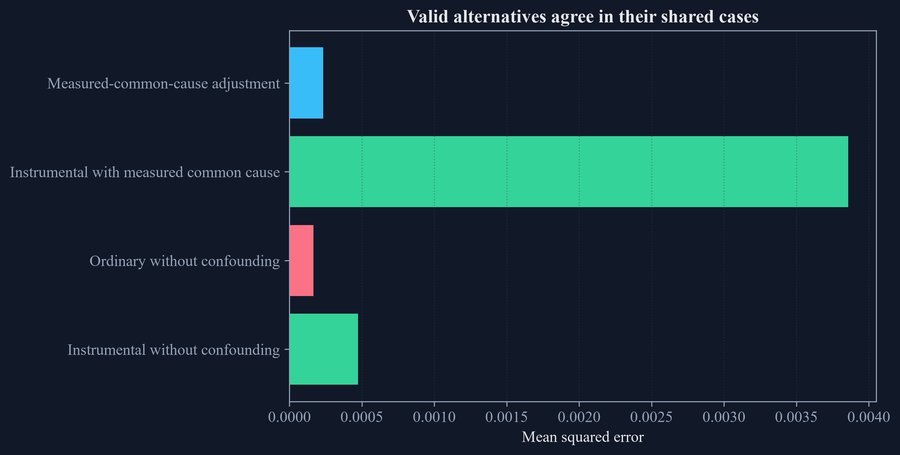

,Case,First-stage F,Set kind,Lower end,Upper end,Bounded,Contains known effect
0,Strong instrument,1917.142989,interval,0.408184,0.577115,True,True
1,Near-irrelevant instrument,0.065627,allreal,-inf,inf,False,True


In [5]:
figure, axis = plt.subplots(figsize=(9.3, 4.8))
axis.barh(limiting_cases["Case"], limiting_cases["Mean squared error"], color=[palette["green"], palette["rose"], palette["green"], palette["cyan"]])
axis.set_xlabel("Mean squared error")
axis.set_title("Valid alternatives agree in their shared cases")
axis.grid(axis="x", alpha=0.4)
figure.tight_layout()
save_figure(figure, "iv_limiting_cases")

set_rng = np.random.default_rng(3)
xs, ys, zs, ws = simulate_iv(4000, gamma=2.5, relevance=1.0, rng=set_rng)
xw, yw, zw, ww = simulate_iv(300, gamma=2.5, relevance=0.01, rng=set_rng)
strong_set = anderson_rubin_set(xs, ys, zs)
weak_set = anderson_rubin_set(xw, yw, zw)
set_examples = pd.DataFrame([
    {"Case": "Strong instrument", "First-stage F": iv_premium(xs, ys, zs).first_stage_f, "Set kind": strong_set.kind, "Lower end": strong_set.lo, "Upper end": strong_set.hi, "Bounded": strong_set.bounded, "Contains known effect": in_anderson_rubin_set(beta_true, xs, ys, zs)},
    {"Case": "Near-irrelevant instrument", "First-stage F": iv_premium(xw, yw, zw).first_stage_f, "Set kind": weak_set.kind, "Lower end": weak_set.lo, "Upper end": weak_set.hi, "Bounded": weak_set.bounded, "Contains known effect": in_anderson_rubin_set(beta_true, xw, yw, zw)},
])
set_examples_book = set_examples[["Case", "First-stage F", "Set kind", "Lower end", "Upper end", "Contains known effect"]]
save_table(set_examples_book, "iv_set_examples", "Robust-set shapes for a strong and a near-irrelevant instrument.", "tab:chapter24-iv-set-examples")
display(set_examples);



#### Strong instrument: bounded set

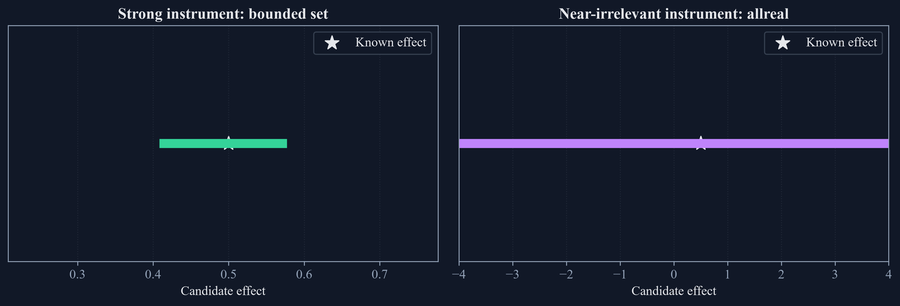

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(11.2, 3.9))
axes[0].hlines(0, strong_set.lo, strong_set.hi, color=palette["green"], linewidth=8)
axes[0].scatter([beta_true], [0], color=palette["text"], marker="*", s=160, label="Known effect")
axes[0].set_xlim(strong_set.lo - 0.2, strong_set.hi + 0.2)
axes[0].set_title("Strong instrument: bounded set")
axes[1].axhline(0, color=palette["violet"], linewidth=8)
axes[1].scatter([beta_true], [0], color=palette["text"], marker="*", s=160, label="Known effect")
axes[1].set_xlim(-4, 4)
axes[1].set_title(f"Near-irrelevant instrument: {weak_set.kind}")
for axis in axes:
    axis.set_yticks([])
    axis.set_xlabel("Candidate effect")
    axis.legend()
    axis.grid(axis="x", alpha=0.4)
figure.tight_layout()
save_figure(figure, "iv_set_examples")

## Local Effects for Compliers

With a binary instrument and monotone treatment response, the Wald ratio identifies the average effect for people whose treatment changes with the instrument:

$$
\beta_{\mathrm{LATE}}
=\frac{\mathbb E[Y\mid Z=1]-\mathbb E[Y\mid Z=0]}
{\mathbb E[X\mid Z=1]-\mathbb E[X\mid Z=0]}
=\mathbb E[Y(1)-Y(0)\mid X(1)>X(0)].
$$

Here, $Z\in\{0,1\}$ is the assigned instrument, $X(z)$ is potential treatment under assignment $z$, $Y(1)-Y(0)$ is the individual treatment effect, and the condition $X(1)>X(0)$ selects compliers. The result is local to that group and need not equal the population average effect.

### Treatment response and effect by compliance group

In [6]:
compliance_rng = np.random.default_rng(240303)
compliance_n = 100000
types = compliance_rng.choice(["Never treated", "Complier", "Always treated"], size=compliance_n, p=[0.20, 0.60, 0.20])
instrument = compliance_rng.integers(0, 2, size=compliance_n)
treatment_zero = (types == "Always treated").astype(int)
treatment_one = (types != "Never treated").astype(int)
treatment_values = np.where(instrument == 1, treatment_one, treatment_zero)
type_effect = np.select([types == "Never treated", types == "Complier", types == "Always treated"], [0.2, 0.8, 2.4])
baseline = compliance_rng.standard_normal(compliance_n)
outcome_values = baseline + type_effect * treatment_values
reduced_form = outcome_values[instrument == 1].mean() - outcome_values[instrument == 0].mean()
first_stage = treatment_values[instrument == 1].mean() - treatment_values[instrument == 0].mean()
wald_effect = reduced_form / first_stage
complier_effect = type_effect[types == "Complier"].mean()
population_effect = type_effect.mean()
compliance_types = pd.DataFrame([{"Group": name, "Share": np.mean(types == name), "Treatment under instrument 0": treatment_zero[types == name].mean(), "Treatment under instrument 1": treatment_one[types == name].mean(), "Group treatment effect": type_effect[types == name].mean()} for name in ("Never treated", "Complier", "Always treated")])
late_comparison = pd.DataFrame([
    {"Quantity": "First-stage treatment change", "Value": first_stage},
    {"Quantity": "Reduced-form outcome change", "Value": reduced_form},
    {"Quantity": "Wald ratio", "Value": wald_effect},
    {"Quantity": "Known complier average effect", "Value": complier_effect},
    {"Quantity": "Known population average effect", "Value": population_effect},
])
save_table(compliance_types, "iv_compliance_types", "Treatment response and effect by compliance group.", "tab:chapter24-iv-compliance-types")
save_table(late_comparison, "iv_late_comparison", "Wald ratio, complier effect, and population effect in a binary experiment.", "tab:chapter24-iv-late-comparison")
display(compliance_types)
display(late_comparison);



,Group,Share,Treatment under instrument 0,Treatment under instrument 1,Group treatment effect
0,Never treated,0.19742,0,0,0.2
1,Complier,0.60148,0,1,0.8
2,Always treated,0.2011,1,1,2.4


,Quantity,Value
0,First-stage treatment change,0.602646
1,Reduced-form outcome change,0.468608
2,Wald ratio,0.777583
3,Known complier average effect,0.8
4,Known population average effect,1.003308


### Only compliers change treatment

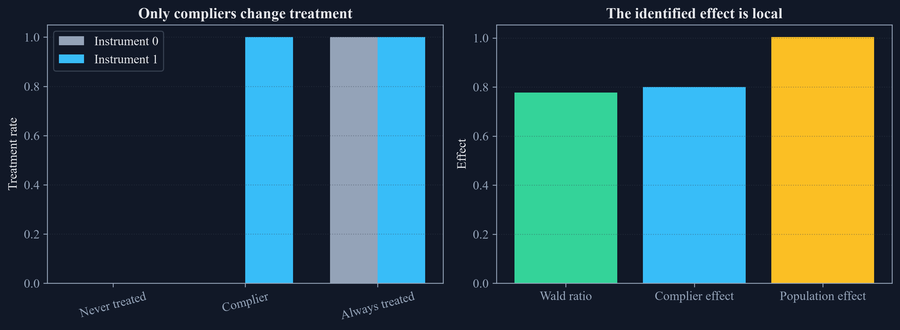

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
index = np.arange(len(compliance_types))
axes[0].bar(index - 0.18, compliance_types["Treatment under instrument 0"], width=0.36, color=palette["muted"], label="Instrument 0")
axes[0].bar(index + 0.18, compliance_types["Treatment under instrument 1"], width=0.36, color=palette["cyan"], label="Instrument 1")
axes[0].set_xticks(index, compliance_types["Group"], rotation=15)
axes[0].set_ylabel("Treatment rate")
axes[0].set_title("Only compliers change treatment")
axes[0].legend()
axes[1].bar(["Wald ratio", "Complier effect", "Population effect"], [wald_effect, complier_effect, population_effect], color=[palette["green"], palette["cyan"], palette["amber"]])
axes[1].set_ylabel("Effect")
axes[1].set_title("The identified effect is local")
for axis in axes:
    axis.grid(axis="y", alpha=0.4)
figure.tight_layout()
save_figure(figure, "iv_compliance_types")

## Checking the method contract at its limits

In [7]:
zero = np.zeros(10)
contract_checks = pd.DataFrame([
    contract_result("Unequal lengths", lambda: iv_premium(np.zeros(9), zero, zero), "ValueError"),
    contract_result("Too few observations", lambda: iv_premium(np.zeros(2), np.zeros(2), np.zeros(2)), "ValueError"),
    contract_result("Invalid confidence level", lambda: anderson_rubin_set(zero, zero, zero, alpha=1.5), "ValueError"),
    contract_result("Two-dimensional treatment", lambda: ols_iv_wedge(np.zeros((10, 2)), zero, zero), "ValueError"),
])
iv_summary = pd.DataFrame([
    {"Question": "Does a large first-stage F prove validity?", "Answer": "No"},
    {"Question": "Is 10 a theorem?", "Answer": "No, it is a practical warning line"},
    {"Question": "Should a weak-instrument point be read alone?", "Answer": "No"},
    {"Question": "Can the robust set be unbounded?", "Answer": "Yes"},
    {"Question": "Is the binary-treatment effect universal?", "Answer": "No, it is local to compliers under the assumptions"},
])
save_table(contract_checks, "iv_contract_checks", "Input checks for the released instrumental-variable calculations.", "tab:chapter24-iv-contract-checks")
save_table(iv_summary, "iv_section_summary", "Main conclusions from the instrumental-variable experiments.", "tab:chapter24-iv-summary")
display(contract_checks)
display(iv_summary)

,Check,Expected result,Observed result,Passed
0,Unequal lengths,Rejected,Rejected,True
1,Too few observations,Rejected,Rejected,True
2,Invalid confidence level,Rejected,Rejected,True
3,Two-dimensional treatment,Rejected,Rejected,True


,Question,Answer
0,Does a large first-stage F prove validity?,No
1,Is 10 a theorem?,"No, it is a practical warning line"
2,Should a weak-instrument point be read alone?,No
3,Can the robust set be unbounded?,Yes
4,Is the binary-treatment effect universal?,"No, it is local to compliers under the assumpt..."


## Tests

In [8]:
assert strong_recovery.loc[strong_recovery["Method"] == "Instrumental", "Mean squared error"].iloc[0] <= 0.05
assert strong_recovery.loc[strong_recovery["Method"] == "Ordinary", "Mean squared error"].iloc[0] >= 0.30
assert strong_recovery.loc[strong_recovery["Method"] == "Noisy proxy adjustment", "Mean squared error"].iloc[0] >= 0.30
assert list(iv_wedge_sweep["Mean wedge"]) == sorted(iv_wedge_sweep["Mean wedge"])
assert ar_sweep["Robust-set coverage"].between(0.90, 0.99).all()
assert ar_sweep.iloc[0]["Bounded-set fraction"] >= 0.98
assert ar_sweep.iloc[-1]["Bounded-set fraction"] <= 0.60
assert ar_sweep.iloc[-1]["Point-estimate mean squared error"] >= 20.0
assert limiting_cases["Mean squared error"].max() <= 0.02
assert strong_set.bounded and not weak_set.bounded
assert abs(wald_effect - complier_effect) < 0.03
assert abs(wald_effect - population_effect) > 0.10
assert contract_checks["Passed"].all()
for stem in ["iv_graph", "iv_demo_strength", "iv_strong_recovery_distributions", "iv_wedge_sweep", "iv_ar_sweep", "iv_limiting_cases", "iv_set_examples", "iv_compliance_types"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["iv_conditions", "iv_structural_parameters", "iv_demo", "iv_strong_recovery", "iv_wedge_sweep", "iv_ar_sweep", "iv_limiting_cases", "iv_set_examples", "iv_compliance_types", "iv_late_comparison", "iv_contract_checks", "iv_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()